In [1]:
import os

# --- 0. RESOURCE LIMITATION (Requested: 16 Threads) ---
# Limits the number of threads used by Numpy/Scipy/FakeSpectra to 16
# This prevents the code from hijacking the entire node.
num_cores = 20
os.environ["OMP_NUM_THREADS"] = "20"
os.environ["NUMEXPR_MAX_THREADS"] = "20"
os.environ["MKL_NUM_THREADS"] = "20"
os.environ["VECLIB_MAXIMUM_THREADS"] = "20"

import numpy as np
import h5py
import sys
import pickle
from tqdm import tqdm
import fake_spectra.spectra as spectra
import matplotlib.pyplot as plt

# --- 0. NEW CONFIGURATION ---
def matplotlib_default_config():
    font = {
        'family' : 'serif',
        'weight' : 'normal',
        'size'   : 14
    }
    rcnew = {
        "mathtext.fontset" : "cm", 
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize" : 24,
        "axes.labelsize" : 24,
        "legend.fontsize" : 20,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.alignment': 'center',
        'xtick.bottom': True,
        'xtick.color': 'black',
        'xtick.direction': 'in',
        'xtick.labelbottom': True,
        'xtick.labelsize': 20,
        'xtick.major.bottom': True,
        'xtick.major.pad': 6.0,
        'xtick.major.size': 10.0,
        'xtick.major.width': 1.5,
        'xtick.minor.bottom': True,
        'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0,
        'xtick.minor.visible': True,
        'xtick.minor.width': 1.0,
        'xtick.top': True,
        'ytick.alignment': 'center_baseline',
        'ytick.color': 'black',
        'ytick.direction': 'in',
        'ytick.labelleft': True,
        'ytick.labelsize': 20,
        'ytick.left': True,
        'ytick.major.left': True,
        'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0,
        'ytick.major.width': 1.5,
        'ytick.minor.left': True,
        'ytick.minor.pad': 3.4,
        'ytick.minor.right': True,
        'ytick.minor.size': 5.0,
        'ytick.minor.visible': True,
        'ytick.minor.width': 1.0,
        'ytick.right': True
    }
    return font, rcnew

# Apply Config
%matplotlib widget 
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

In [38]:
# ================= 1. SETUP & PARAMETERS =================
BASE_DIR = "/home/STORAGE"
SIMULATIONS = [
    {"name": "TNG50-4", "color": "#1f77b4", "marker": "o"}, # Blue
    {"name": "TNG50-3", "color": "#ff7f0e", "marker": "^"}, # Orange
    {"name": "TNG50-2", "color": "#2ca02c", "marker": "s"}  # Green
]

SNAP_NUM = 25   # Redshift z=3
HUBBLE_H = 0.6774

# Define mass bins (Log10 Solar Masses)
# Using 100 bins for higher resolution as requested
BINS_LOG = np.linspace(8.5, 13.5, 100) 
BIN_CENTERS = (BINS_LOG[:-1] + BINS_LOG[1:]) / 2
BIN_WIDTH = BINS_LOG[1] - BINS_LOG[0]

# Dictionary to store processed data (separation of concerns)
processed_data = {}

In [41]:
BINS_LOG

array([ 8.5       ,  8.55050505,  8.6010101 ,  8.65151515,  8.7020202 ,
        8.75252525,  8.8030303 ,  8.85353535,  8.9040404 ,  8.95454545,
        9.00505051,  9.05555556,  9.10606061,  9.15656566,  9.20707071,
        9.25757576,  9.30808081,  9.35858586,  9.40909091,  9.45959596,
        9.51010101,  9.56060606,  9.61111111,  9.66161616,  9.71212121,
        9.76262626,  9.81313131,  9.86363636,  9.91414141,  9.96464646,
       10.01515152, 10.06565657, 10.11616162, 10.16666667, 10.21717172,
       10.26767677, 10.31818182, 10.36868687, 10.41919192, 10.46969697,
       10.52020202, 10.57070707, 10.62121212, 10.67171717, 10.72222222,
       10.77272727, 10.82323232, 10.87373737, 10.92424242, 10.97474747,
       11.02525253, 11.07575758, 11.12626263, 11.17676768, 11.22727273,
       11.27777778, 11.32828283, 11.37878788, 11.42929293, 11.47979798,
       11.53030303, 11.58080808, 11.63131313, 11.68181818, 11.73232323,
       11.78282828, 11.83333333, 11.88383838, 11.93434343, 11.98

In [44]:
# ================= 2. DATA LOADING & PROCESSING =================
for sim in SIMULATIONS:
    sim_name = sim['name']
    
    # Define paths
    group_dir = os.path.join(BASE_DIR, sim_name, f"groups_{SNAP_NUM:03d}")
    f0_path = os.path.join(group_dir, f"fof_subhalo_tab_{SNAP_NUM:03d}.0.hdf5")
        
    # Get metadata (number of files)
    with h5py.File(f0_path, 'r') as f:
        num_files = int(f['Header'].attrs['NumFiles'])
    
    # List to collect masses from all chunks
    mass_collector = []
    
    # Loop over chunks
    for i in tqdm(range(num_files), desc=f"Reading {sim_name}", leave=False):
        file_path = os.path.join(group_dir, f"fof_subhalo_tab_{SNAP_NUM:03d}.{i}.hdf5")
        
        with h5py.File(file_path, 'r') as f:
            # Check if group data exists in this file
            if 'Group' in f and 'Group_M_Crit200' in f['Group']:
                m_code = f['Group']['Group_M_Crit200'][:]
                mass_collector.append(m_code)

    # Concatenate results
    if len(mass_collector) > 0:
        all_masses = np.concatenate(mass_collector)
    else:
        all_masses = np.array([])
        
    # Process Units: Convert to Physical Solar Masses
    # (Mass code * 10^10) / h
    masses_phys = (all_masses * 1e10) / HUBBLE_H
    
    # Filter physical values (remove zeros or negatives)
    masses_phys = masses_phys[masses_phys > 0]
    
    # Calculate Histogram (The Mass Function)
    # counts = number of halos in each bin
    counts, _ = np.histogram(np.log10(masses_phys), bins=BINS_LOG)
    
    # Calculate Differential Mass Function: dN / dlogM
    # This normalizes by the bin width
    dn_dlogm = counts / BIN_WIDTH
    
    # Store in our dictionary
    processed_data[sim_name] = {
        "x": BIN_CENTERS,
        "y": dn_dlogm,
        "raw_count": np.sum(counts) # Just for info
    }

print("✅ Data Processing Complete.")

✅ Data Processing Complete.


🎨 Generating Plot...


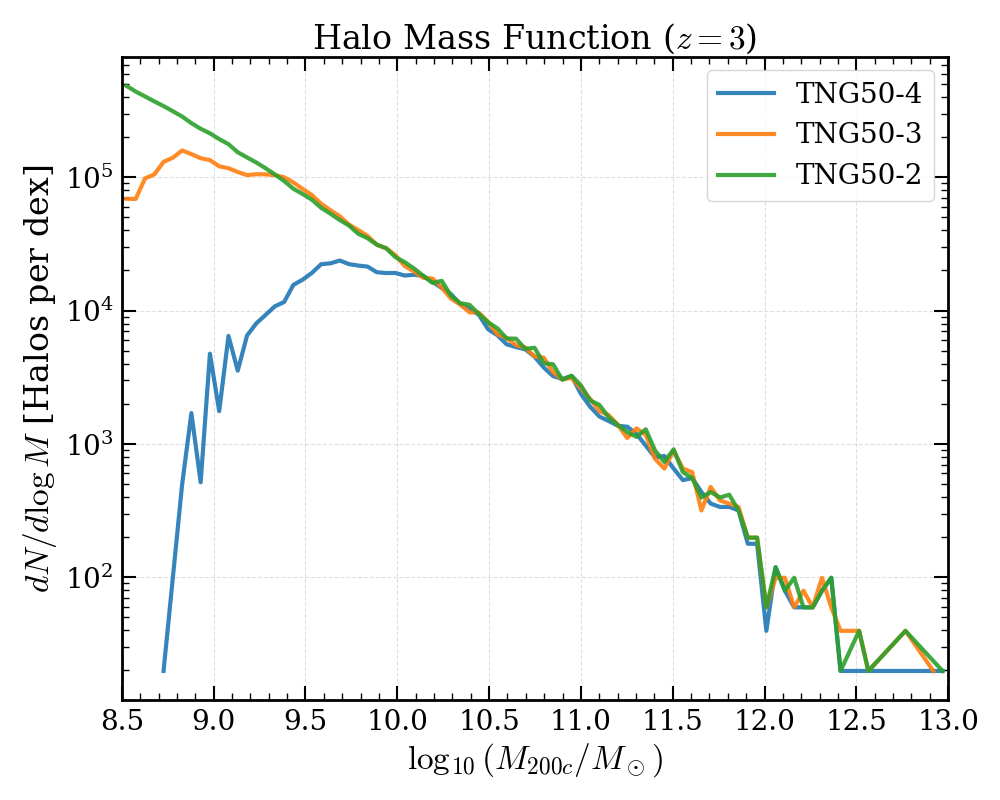

In [45]:
# ================= 3. PLOTTING =================
print("🎨 Generating Plot...")

plt.figure(figsize=(10, 8))

for sim in SIMULATIONS:
    sim_name = sim['name']
    
    if sim_name not in processed_data:
        continue
        
    data = processed_data[sim_name]
    x = data["x"]
    y = data["y"]
    
    # Mask zeros to ensure clean log-log plot (no drop to -infinity)
    mask = y > 0
    
    # Plot using smooth lines
    plt.plot(x[mask], y[mask], 
             linestyle='-', 
             linewidth=3, 
             color=sim['color'], 
             label=sim_name,
             alpha=0.9)

# Formatting
plt.yscale('log')
plt.xlabel(r"$\log_{10}(M_{200c} / M_\odot)$")
plt.ylabel(r"$dN / d\log M$ [Halos per dex]")
plt.title(r"Halo Mass Function ($z=3$)")
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.4)

# Adjust limits to focus on the relevant range
plt.xlim(8.5, 13)
#plt.ylim(1, 2e5) 

plt.tight_layout()
plt.show()